# 01 – Portafolio
**Lab #2 – Derivados Financieros** · Puntos 1 a 5 (proceso de creación del portafolio: 20 % + R5 y R6)

## Importar librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import yfinance as yf

RAW = Path("../data/raw")
PROC = Path("../data/processed")

## Punto 1 – Análisis fundamental (R1 – 5 %)

### ¿Cómo escogimos las acciones?
CSCO y ADI vienen desde la primera versión del lab. En el grupo las escogimos sin hacerles análisis fundamental primero; abajo mostramos por qué igual tiene sentido quedarnos con ellas.

AMGN sí tiene su historia. En la asesoría del 09/11/2026 el profe nos pidió cambiar PYPL. Para buscar el reemplazo filtramos las 101 acciones del Nasdaq-100 que aparecen en investing.com (notebook `00_screening_reemplazo`): 10 años completos de datos, retorno positivo en 2026 y mínimo 6 de 9 años en verde. Pasaron 46.
Las que más subieron en 2026 eran casi todas de chips (MU, AMD, MRVL), que se mueven muy parecido a ADI y le suben el riesgo al portafolio. Nos quedamos con AMGN porque es de salud, tiene correlación baja con CSCO (0,34) y con ADI (0,31) y su peor caída en 10 años fue de 25 %, la menor de las 46.
Lo que nos preocupa de AMGN es la deuda que le quedó por la compra de Horizon en 2023. Por eso en el 1.2 le miramos la deuda con lupa.

Fuente de los componentes del índice: [investing.com – Nasdaq-100 components](https://www.investing.com/indices/nq-100-components), consultada el 10/11/2026. Las tres están en el Nasdaq-100.

Todo lo de este punto va con corte al 30/10/2026, el día que arranca la inversión. Si una empresa publicó resultados después de esa fecha (AMGN publicó su tercer trimestre el 03/11/2026), esos datos no se usan, porque el gerente no los tenía ese día.

### 1.0 Datos
Leemos lo que dejó listo `00_datos` (precios ya revisados). Así este notebook usa exactamente los datos del punto 0 y no los CSV viejos que traían PYPL.
Ojo: antes hay que correr `00_datos` completo, porque es el que guarda los archivos `_v2`.

In [ ]:
ACC = ["CSCO", "ADI", "AMGN"]                     # las 3 del portafolio (AMGN entró por PYPL)
MERCADO = "^NDX"                                  # el índice, para comparar y para las betas
CORTE = pd.Timestamp("2026-10-30")                # día en que arranca la inversión

def leer(nombre):                                 # lee una tabla que dejó 00_datos
    return pd.read_csv(PROC / nombre, index_col=0, parse_dates=True).astype(float)

close = leer("close_v2.csv")                      # cierre normal (solo precio)
adj = leer("adj_v2.csv")                          # cierre ajustado (precio + dividendos)
divs = leer("divs_v2.csv")                        # dividendos pagados cada día

# Revisiones rápidas para no trabajar con datos que no son
assert list(adj.columns) == ACC + [MERCADO], "ojo: las columnas no son CSCO, ADI, AMGN, ^NDX"
assert adj.index[-1] == CORTE, "ojo: la serie no termina el 30/10/2026"
assert adj.notna().all().all(), "ojo: hay datos vacíos"

f = CORTE                                         # nombre corto que usamos más abajo
print("Datos:", list(adj.columns), "|", adj.index[0].date(), "→", f.date(), "|", len(adj), "días")

Datos: ['CSCO', 'ADI', 'AMGN', '^NDX'] | 2016-10-31 → 2026-10-30 | 2514 días


### 1.1 ¿Cómo les ha ido en el precio?
Miramos el precio al 30/10/2026, qué tan lejos quedó del máximo de las últimas 52 semanas, cuánto rindió en 2026 y a 1, 3 y 5 años, y la peor caída del último año.
Para los retornos de 1, 3 y 5 años usamos el precio ajustado (con dividendos) y comparamos todo contra el Nasdaq-100.

,Precio 30/10/2026,Máx 52s,Mín 52s,Dist. al máx,Ret. precio 2026,Ret. total 1a,Ret. total 3a,Ret. total 5a,Peor caída 1a
CSCO,104.51,130.00,71.04,-19.6%,35.7%,46.0%,118.6%,114.1%,-19.0%
ADI,417.11,445.48,225.20,-6.4%,53.8%,81.3%,180.4%,161.4%,-20.7%
AMGN,466.01,466.01,292.00,0.0%,42.4%,64.0%,93.7%,163.1%,-16.6%
^NDX,"28,384.85","31,224.47","22,953.38",-9.1%,12.4%,10.3%,98.0%,79.1%,-11.8%


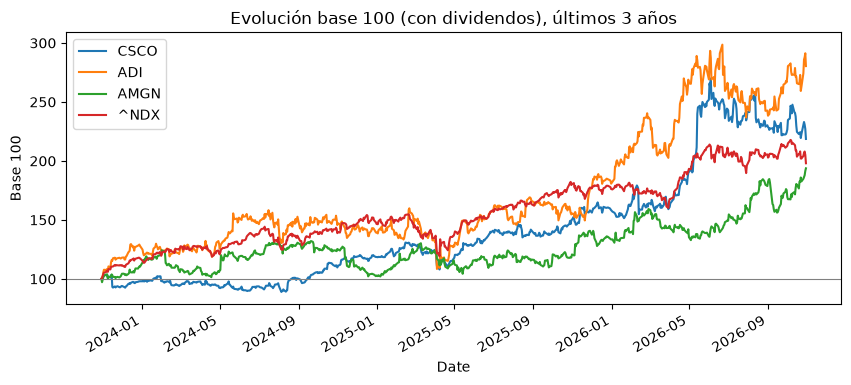

In [ ]:
def ret(df, años):                                        # retorno entre hace N años y el 30/10/2026
    p0 = df.loc[:f - pd.DateOffset(years=años)].iloc[-1]  # último precio que había hace N años
    return df.iloc[-1] / p0 - 1                           # P_t / P_0 − 1

ult_año = close.loc[f - pd.DateOffset(years=1):]          # últimas 52 semanas (solo precio)
adj_año = adj.loc[f - pd.DateOffset(years=1):]            # lo mismo pero con dividendos
evol = pd.DataFrame({
    "Precio 30/10/2026": close.iloc[-1],
    "Máx 52s": ult_año.max(),
    "Mín 52s": ult_año.min(),
    "Dist. al máx": close.iloc[-1] / ult_año.max() - 1,              # qué tan abajo del máximo está
    "Ret. precio 2026": close.iloc[-1] / close.loc[:"2025-12-31"].iloc[-1] - 1,
    "Ret. total 1a": ret(adj, 1),
    "Ret. total 3a": ret(adj, 3),
    "Ret. total 5a": ret(adj, 5),
    "Peor caída 1a": (adj_año / adj_año.cummax() - 1).min(),        # máxima caída desde un pico
})
display(evol.style.format({"Precio 30/10/2026": "{:,.2f}", "Máx 52s": "{:,.2f}", "Mín 52s": "{:,.2f}"})
        .format("{:.1%}", subset=evol.columns[3:]))

base100 = adj.loc[f - pd.DateOffset(years=3):]                     # últimos 3 años
(base100 / base100.iloc[0] * 100).plot(figsize=(10, 4),
        title="Evolución base 100 (con dividendos), últimos 3 años")
plt.axhline(100, color="grey", lw=0.8); plt.ylabel("Base 100"); plt.show()

### Lectura de la evolución del precio
Las tres le ganaron de lejos al Nasdaq-100 en el último año: ADI +81,3 %, AMGN +64,0 % y CSCO +46,0 %, contra +10,3 % del índice (retorno total, con dividendos).

ADI es la que mejor le ha ido a 1, 3 y 5 años y quedó a 6,4 % de su máximo de 52 semanas. Es la más de crecimiento, pero también la que más duro cae: en los últimos 3 años llegó a perder 32 % desde un pico (abril de 2025).

AMGN cerró el 30/10/2026 justo en su máximo del año (USD 466,01). Casi toda la subida fuerte vino desde julio de 2026 (pasó de unos 362 a 466 dólares). A 3 años rindió 93,7 %, un poquito menos que el índice (98,0 %), pero a 5 años le gana con 163,1 % contra 79,1 %. Lo que más nos sirve para el portafolio es que su peor caída del último año fue de 16,6 %, la menor de las tres.

CSCO es la que llega más golpeada al 30/10. Pegó un salto en abril y mayo de 2026 (de unos 78 a 120 dólares), pero desde junio viene bajando y está 19,6 % por debajo de su máximo. Aun así lleva +46 % en el año.

Para el portafolio esto quiere decir que no hay una sola acción cargando todo: ADI pone el crecimiento, AMGN está en su mejor momento pero con caídas más suaves y CSCO llega en corrección. Que no suban y bajen al tiempo ya es una pista de la diversificación que vamos a medir en el punto 2.

### 1.2 Situación financiera y deuda
Además de cuánto vende y cuánto gana cada empresa, la idea es ver si puede con su deuda. Esto importa sobre todo por AMGN, que se endeudó para comprar Horizon en 2023.

Usamos tres medidas:
- **Deuda neta / EBITDA** = (deuda total − caja e inversiones de corto plazo) / EBITDA de 12 meses. Dice cuántos años de EBITDA necesita la empresa para pagar la deuda. Una regla común: menos de 2 veces es cómodo, entre 2 y 3 hay que vigilarla y más de 3 es alta.
- **Cobertura de intereses** = EBIT / gasto por intereses. Dice cuántas veces alcanza la utilidad operativa para pagar los intereses. Más de 8 veces es holgado; menos de 3 ya es apretado.
- **Flujo de caja libre (FCF)** = flujo de caja operativo − capex (lo que invierte en planta y equipo). Es la plata que de verdad queda para pagar deuda y dividendos. Lo comparamos contra la deuda neta y contra los dividendos que pagó.

Para cumplir con el corte al 30/10/2026, sumamos los últimos 4 trimestres **publicados antes de esa fecha** y tomamos el último balance publicado. El código mira la fecha en que cada empresa publicó cada trimestre y deja por fuera lo que salió después (por ejemplo, el tercer trimestre de AMGN, publicado el 03/11/2026).

Los estados financieros salen de Yahoo Finance (yfinance), que los toma de los reportes trimestrales (10-Q y 10-K) de cada empresa ante la SEC. La primera vez se descargan y se guardan en `data/raw/`; después siempre se lee esa copia, para que el resultado no cambie.

In [ ]:
from datetime import date
ARCH_EST = RAW / "estados_trimestrales_v2.csv"    # estados financieros trimestrales de las 3
ARCH_FECHAS = RAW / "fechas_resultados_v2.csv"    # cuándo publicó cada trimestre (y su EPS)

if not ARCH_EST.exists():                         # solo la primera vez: bajar de Yahoo y guardar
    filas, fechas = [], []
    for t in ACC:
        tk = yf.Ticker(t)
        for estado, tabla in [("resultados", tk.quarterly_income_stmt),
                              ("balance", tk.quarterly_balance_sheet),
                              ("caja", tk.quarterly_cashflow)]:
            larga = tabla.T.stack().reset_index()                 # una fila por (trimestre, cuenta)
            larga.columns = ["cierre_trimestre", "cuenta", "valor"]
            larga["ticker"], larga["estado"] = t, estado
            filas.append(larga)
        ed = tk.get_earnings_dates(limit=16).reset_index()        # fechas de publicación + EPS reportado
        ed.columns = ["fecha_publicacion"] + list(ed.columns[1:])
        ed["ticker"] = t
        fechas.append(ed)
    pd.concat(filas).to_csv(ARCH_EST, index=False)
    pd.concat(fechas).to_csv(ARCH_FECHAS, index=False)
    (RAW / "estados_fecha_descarga.txt").write_text(str(date.today()))

est = pd.read_csv(ARCH_EST, parse_dates=["cierre_trimestre"])
fch = pd.read_csv(ARCH_FECHAS)
fch["fecha_publicacion"] = pd.to_datetime(fch["fecha_publicacion"], utc=True).dt.tz_localize(None).dt.normalize()
print("Estados descargados el:", (RAW / "estados_fecha_descarga.txt").read_text())

def publicado(t, cierre):                         # fecha en que salió el trimestre que cerró en 'cierre'
    d = fch.loc[(fch.ticker == t) & (fch.fecha_publicacion > cierre), "fecha_publicacion"]
    return d.min()                                # el primer anuncio después del cierre

def cuenta(t, estado, nombres):                   # serie trimestral de una cuenta, solo lo publicado al corte
    for n in nombres:                             # Yahoo a veces le cambia el nombre a la cuenta
        x = est[(est.ticker == t) & (est.estado == estado) & (est.cuenta == n)]
        if len(x): break
    x = x.set_index("cierre_trimestre")["valor"].sort_index().dropna()
    return x[[publicado(t, c) <= CORTE for c in x.index]]

def ttm(t, estado, *nombres):                     # suma de los últimos 4 trimestres (lo que pasó en 12 meses)
    x = cuenta(t, estado, nombres).tail(4)
    assert len(x) == 4 and (x.index[-1] - x.index[0]).days < 300, f"{t}: no hay 4 trimestres seguidos de {nombres[0]}"
    return x.sum()

def ultimo(t, *nombres):                          # saldo del último balance publicado (foto, no se suma)
    return cuenta(t, "balance", nombres).iloc[-1]

# Qué trimestres quedaron dentro, para revisarlo a ojo
for t in ACC:
    q = cuenta(t, "resultados", ["Total Revenue"]).tail(4)
    print(f"{t}: trimestres usados →", [d.date() for d in q.index],
          "| último publicado el", publicado(t, q.index[-1]).date())

c:\Users\Lion-\miniforge3\envs\lab2-derivados\Lib\site-packages\yfinance\base.py:716: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={'Surprise (%)': 'Surprise(%)'}, inplace=True)
c:\Users\Lion-\miniforge3\envs\lab2-derivados\Lib\site-packages\yfinance\base.py:716: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={'Surprise (%)': 'Surprise(%)'}, inplace=True)


Estados descargados el: 2026-11-10
CSCO: trimestres usados → [datetime.date(2025, 10, 31), datetime.date(2026, 1, 31), datetime.date(2026, 4, 30), datetime.date(2026, 7, 31)] | último publicado el 2026-08-12
ADI: trimestres usados → [datetime.date(2025, 10, 31), datetime.date(2026, 1, 31), datetime.date(2026, 4, 30), datetime.date(2026, 7, 31)] | último publicado el 2026-08-19
AMGN: trimestres usados → [datetime.date(2025, 9, 30), datetime.date(2025, 12, 31), datetime.date(2026, 3, 31), datetime.date(2026, 6, 30)] | último publicado el 2026-08-04


c:\Users\Lion-\miniforge3\envs\lab2-derivados\Lib\site-packages\yfinance\base.py:716: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={'Surprise (%)': 'Surprise(%)'}, inplace=True)


In [ ]:
fund = {}
for t in ACC:
    ingresos = ttm(t, "resultados", "Total Revenue")
    ebit = ttm(t, "resultados", "EBIT", "Operating Income")
    ebitda = ttm(t, "resultados", "EBITDA", "Normalized EBITDA")
    intereses = abs(ttm(t, "resultados", "Interest Expense", "Interest Expense Non Operating"))
    utilidad = ttm(t, "resultados", "Net Income", "Net Income Common Stockholders")
    fco = ttm(t, "caja", "Operating Cash Flow")
    capex = abs(ttm(t, "caja", "Capital Expenditure"))
    div_pagados = abs(ttm(t, "caja", "Cash Dividends Paid", "Common Stock Dividend Paid"))
    deuda = ultimo(t, "Total Debt")
    caja = ultimo(t, "Cash Cash Equivalents And Short Term Investments", "Cash And Cash Equivalents")
    fcf = fco - capex                                     # flujo de caja libre
    fund[t] = {
        "Ingresos 12m": ingresos, "Margen operativo": ebit / ingresos, "Margen neto": utilidad / ingresos,
        "ROE": utilidad / ultimo(t, "Stockholders Equity"),
        "Caja": caja, "Deuda total": deuda, "Deuda neta": deuda - caja, "EBITDA 12m": ebitda,
        "Deuda neta / EBITDA": (deuda - caja) / ebitda,
        "Cobertura de intereses": ebit / intereses,
        "FCF 12m": fcf, "FCF / ingresos": fcf / ingresos,
        "FCF / deuda neta": fcf / (deuda - caja),           # qué parte de la deuda neta se paga en un año
        "FCF / dividendos": fcf / div_pagados,              # cuántas veces alcanza la caja para el dividendo
        "Razón corriente": ultimo(t, "Current Assets") / ultimo(t, "Current Liabilities"),
    }
fund = pd.DataFrame(fund)
fund.to_csv(PROC / "fundamentales_v2.csv")                 # insumo del informe

usd = ["Ingresos 12m", "Caja", "Deuda total", "Deuda neta", "EBITDA 12m", "FCF 12m"]
pct = ["Margen operativo", "Margen neto", "ROE", "FCF / ingresos", "FCF / deuda neta"]
veces = ["Deuda neta / EBITDA", "Cobertura de intereses", "FCF / dividendos", "Razón corriente"]
tabla = fund.copy().astype(object)
tabla.loc[usd] = (fund.loc[usd] / 1e6).map(lambda v: f"{v:,.0f}")     # millones de USD
tabla.loc[pct] = fund.loc[pct].map(lambda v: f"{v:.1%}")
tabla.loc[veces] = fund.loc[veces].map(lambda v: f"{v:.2f}x")
tabla.index = [f"{i} (USD M)" if i in usd else i for i in tabla.index]
print("Fuente: Yahoo Finance (estados trimestrales de la SEC). Últimos 4 trimestres publicados al 30/10/2026.")
display(tabla)

Fuente: Yahoo Finance (estados trimestrales de la SEC). Últimos 4 trimestres publicados al 30/10/2026.


,CSCO,ADI,AMGN
Ingresos 12m (USD M),"63,325","13,882","38,095"
Margen operativo,27.6%,36.4%,34.0%
Margen neto,21.0%,29.8%,23.0%
ROE,26.4%,12.3%,74.8%
Caja (USD M),"15,918","2,325","13,989"
Deuda total (USD M),"29,533","9,122","57,304"
Deuda neta (USD M),"13,615","6,797","43,315"
EBITDA 12m (USD M),"20,019","7,026","17,622"
Deuda neta / EBITDA,0.68x,0.97x,2.46x
Cobertura de intereses,11.89x,14.41x,4.86x


### Lectura de la situación financiera
CSCO y ADI están tranquilas con la deuda: deuda neta/EBITDA de 0,68x y 0,97x, y la utilidad operativa les alcanza 11,9 y 14,4 veces para pagar intereses. Con la caja libre de un solo año pagarían el 94 % (CSCO) y el 73 % (ADI) de lo que deben en neto.

AMGN es otra historia, y era justo lo que queríamos mirar. Debe USD 57.304 M y tiene USD 13.989 M en caja, o sea una deuda neta de USD 43.315 M, que son 2,46 veces su EBITDA. Eso está en zona de vigilar pero no es alarmante. La cobertura de intereses es de 4,86x: alcanza, pero con mucho menos colchón que las otras dos. Con su caja libre de un año pagaría el 23,5 % de la deuda neta, o sea que necesitaría unos 4 años para salir de ella.

Lo que nos deja tranquilos con AMGN: genera mucha caja (FCF de USD 10.175 M, el 26,7 % de lo que vende), tiene márgenes altos (34 % operativo) y su caja libre cubre 1,93 veces los dividendos, igual que CSCO. La liquidez de corto plazo, que nos preocupaba, sale bien: razón corriente de 1,37, la mejor de las tres. Su ROE de 74,8 % hay que tomarlo con pinzas, porque tiene poco patrimonio frente a la deuda y eso lo infla.

En resumen, la deuda de AMGN es un riesgo real pero manejable: la empresa la puede pagar con su propia caja sin tocar el dividendo. Para un portafolio a 4 años lo tenemos presente.

### 1.3 ¿Qué precio esperamos en un año?
Usamos el mismo método de la primera versión, múltiplos de utilidades: si el mercado le sigue pagando a la acción el mismo P/E de hoy, el precio dentro de un año sería ese P/E por la utilidad por acción (EPS) que esperan los analistas.

$$\text{Precio objetivo} = \frac{P_0}{EPS_{12m}} \times E[EPS_{\text{próximo año}}]$$

- $P_0$: precio al 30/10/2026.
- $EPS_{12m}$: EPS ajustado de los últimos 4 trimestres publicados antes del 30/10 (para AMGN no entra el tercer trimestre de 2026).
- $E[EPS]$: consenso de analistas de Yahoo para el año fiscal que termina más cerca del 30/10/2027.

Una limitación: Yahoo no guarda el consenso histórico, así que el consenso es el del día de la descarga. Para AMGN ese consenso ya incorpora los resultados del 03/11/2026. Lo dejamos dicho y no se puede corregir con datos gratuitos.

In [ ]:
# Año fiscal que termina más cerca del 30/10/2027 (horizonte de 1 año)
periodo = {"CSCO": "0y",    # CSCO cierra el año en julio → FY2027 (jul-2027)
           "ADI": "+1y",    # ADI cierra a inicios de noviembre → FY2027 (nov-2027)
           "AMGN": "+1y"}   # AMGN cierra en diciembre → 2027

ARCH_CONS = RAW / "consenso_eps_v2.csv"
if not ARCH_CONS.exists():                         # solo la primera vez: bajar el consenso y guardarlo
    pd.concat({t: yf.Ticker(t).earnings_estimate for t in ACC}).to_csv(ARCH_CONS)
cons = pd.read_csv(ARCH_CONS, index_col=[0, 1])    # índice: (ticker, periodo)

precio = close.loc[CORTE, ACC]
filas = {}
for t in ACC:
    rep = (fch[(fch.ticker == t) & (fch.fecha_publicacion <= CORTE)]
           .dropna(subset=["Reported EPS"]).sort_values("fecha_publicacion"))
    eps_12m = rep["Reported EPS"].tail(4).sum()    # EPS ajustado de los 4 trimestres publicados al corte
    e = cons.loc[(t, periodo[t])]                  # consenso: promedio, mínimo y máximo de los analistas
    pe = precio[t] / eps_12m                       # P/E al 30/10/2026
    filas[t] = {"Precio 30/10/2026": precio[t], "EPS 12m": eps_12m, "P/E": pe,
                "EPS esperado": e["avg"], "Precio objetivo": pe * e["avg"],
                "Escenario bajo": pe * e["low"], "Escenario alto": pe * e["high"],
                "Retorno esperado": pe * e["avg"] / precio[t] - 1, "N.º analistas": e["numberOfAnalysts"]}
exp_pe = pd.DataFrame(filas).T
exp_pe.to_csv(PROC / "expectativa_PE_v2.csv")

print("Fuente: Yahoo Finance (EPS reportado y consenso de analistas)")
display(exp_pe.style.format("{:,.2f}").format("{:.1%}", subset=["Retorno esperado"])
        .format("{:,.0f}", subset=["N.º analistas"]))

Fuente: Yahoo Finance (EPS reportado y consenso de analistas)


,Precio 30/10/2026,EPS 12m,P/E,EPS esperado,Precio objetivo,Escenario bajo,Escenario alto,Retorno esperado,N.º analistas
CSCO,104.51,4.32,24.19,5.15,124.49,122.17,135.72,19.1%,28
ADI,417.11,11.26,37.04,16.50,611.25,531.33,666.78,46.5%,30
AMGN,466.01,22.37,20.83,24.99,520.66,489.97,553.30,11.7%,33


### Lectura de la expectativa a un año
- CSCO: P/E de 24,2x, precio objetivo de USD 124,49 (+19,1 %), con rango entre 122,17 y 135,72.
- ADI: P/E de 37,0x, precio objetivo de USD 611,25 (+46,5 %), con rango entre 531,33 y 666,78.
- AMGN: P/E de 20,8x, precio objetivo de USD 520,66 (+11,7 %), con rango entre 489,97 y 553,30 (33 analistas).

AMGN es la más barata frente a sus utilidades y la que menos promete subir. Pero incluso en el escenario bajo de los analistas sube (+5,1 %). Eso cuadra con el papel que le damos: no es la que va a jalar el retorno, es la que da estabilidad.

ADI promete mucho porque los analistas esperan que su EPS crezca 46 % en un año, y además es la más cara (37x). Si el mercado le baja el múltiplo, ese retorno se puede quedar en nada, porque el método supone que el P/E se mantiene igual.

CSCO queda en el medio: +19 % esperado y hasta su escenario bajo da +16,9 %.

CSCO y ADI dan exactamente igual que en la primera versión, lo que confirma que estamos usando la información disponible al 30/10/2026.

### 1.4 Resumen de las tres empresas

| | CSCO – Cisco Systems | ADI – Analog Devices | AMGN – Amgen |
|---|---|---|---|
| Qué hace | Equipos de redes y ciberseguridad para empresas y centros de datos. | Chips que convierten señales del mundo físico (temperatura, sonido, energía, movimiento) en datos. | Biotecnológica: desarrolla y vende medicamentos biológicos para enfermedades serias. |
| Sector | Tecnología · equipos de comunicación | Tecnología · semiconductores | Salud · biotecnología |
| De dónde saca la plata | Más de la mitad son equipos de red; el resto es seguridad, colaboración y contratos de soporte, que dan ingresos estables. | Casi la mitad va a la industria (fábricas, defensa, medición); el resto a carros, centros de datos y electrónica de consumo. | Venta de medicamentos: colesterol (Repatha), huesos (Prolia, Evenity), inflamación (Enbrel, Otezla), cáncer y enfermedades raras (lo que trajo la compra de Horizon). |
| Precio (1.1) | +46,0 % en el año, pero 19,6 % debajo de su máximo: viene corrigiendo desde junio. | +81,3 % en el año, cerca de su máximo (−6,4 %). | +64,0 % en el año y cerró en su máximo; la caída más suave de las tres (−16,6 %). |
| Finanzas (1.2) | Ingresos USD 63.325 M, margen operativo 27,6 %, FCF USD 12.767 M. Deuda baja (0,68x EBITDA). | Margen operativo 36,4 % y FCF del 35,6 % de las ventas. Deuda baja (0,97x). | Ingresos USD 38.095 M, margen operativo 34,0 %, FCF USD 10.175 M. Deuda alta pero pagable (2,46x; intereses cubiertos 4,9x). |
| Expectativa a 1 año (1.3) | USD 124,49 (+19,1 %) | USD 611,25 (+46,5 %) | USD 520,66 (+11,7 %) |
| Riesgos | Que se frene el gasto en IA y redes. | Es cíclica y está cara (P/E 37x). | Biosimilares que compiten con Prolia, recortes de precios de Medicare en EE. UU. y la deuda. |
| Para qué está en el portafolio | Estabilidad y renta (dividendo 1,6 %). | Crecimiento. | Defensa: es de salud, se mueve poco con la tecnología y paga el mayor dividendo (2,1 %). |

**Decisión:** nos quedamos con CSCO, ADI y AMGN. Son tres negocios del mismo índice pero muy distintos (redes, chips, medicamentos), y eso se nota en las correlaciones del punto 2. ADI pone el crecimiento, CSCO la estabilidad y AMGN la defensa, que es justo lo que necesita un portafolio de mínima varianza. Las tres pagan dividendo y generan caja de sobra para pagarlo. El punto débil es la deuda de AMGN, que es manejable con su propia caja, y la tenemos presente cuando veamos cuánto peso le da el optimizador.

## Punto 2 – Estadística descriptiva (R2 – 5 %)

### 2.0 ¿Por qué todo en mensual?
Después de la asesoría decidimos trabajar todo el laboratorio con datos mensuales (k = 12). La razón es de unidades: el VaR es mensual, la simulación del futuro es mensual y la cuenta de margen se liquida cada mes. Si estimamos la media y la covarianza con datos diarios y luego simulamos por meses, toca andar convirtiendo y es fácil embarrarla. Con todo mensual, lo que sale aquí entra derecho a los puntos 3 al 12.

El costo es que con 10 años solo hay 120 retornos mensuales (con diarios eran 2.513), así que las estimaciones son menos precisas. Los datos diarios solo aparecen abajo como comparación.

In [8]:
INICIO = f - pd.DateOffset(years=10)                  # 10 años hasta el 30/10/2026
k = 12                                                # meses en un año
p_m = adj.loc[INICIO:].resample("ME").last()          # precio ajustado del último día de bolsa de cada mes
r_m = np.log(p_m / p_m.shift(1)).dropna()             # retorno log mensual: ln(P_t / P_t-1)
r_m.to_csv(PROC / "retornos_mensuales_v2.csv")        # entra a los puntos 3, 4, 5 y a la simulación

r_d = np.log(adj / adj.shift(1)).dropna()             # diarios, SOLO para comparar la volatilidad

est_m = pd.DataFrame({
    "Media mensual": r_m.mean(),                      # r̄: retorno log promedio de un mes
    "Desv. mensual": r_m.std(),                       # σ de un mes (muestral, n − 1)
    "Retorno anual": np.exp(r_m.mean() * k) - 1,      # μ = e^(r̄·12) − 1
    "Volatilidad anual": r_m.std() * np.sqrt(k),      # σ_anual = σ_mensual · √12
    "Meses en verde": (r_m > 0).mean(),               # % de meses con retorno positivo
    "Peor mes": r_m.min(),
    "Mejor mes": r_m.max(),
    "Asimetría": r_m.skew(),                          # 0 si es simétrica como la normal
    "Curtosis exceso": r_m.kurt(),                    # 0 en la normal; > 0 = colas más gordas
    "Vol. anual con diarios (ref.)": r_d.std() * np.sqrt(252),
})
print(f"Retornos mensuales: {len(r_m)} meses · {r_m.index[0]:%b-%Y} → {r_m.index[-1]:%b-%Y}")
display(est_m.style.format("{:.2%}").format("{:.2f}", subset=["Asimetría", "Curtosis exceso"]))

Retornos mensuales: 120 meses · Nov-2016 → Oct-2026


,Media mensual,Desv. mensual,Retorno anual,Volatilidad anual,Meses en verde,Peor mes,Mejor mes,Asimetría,Curtosis exceso,Vol. anual con diarios (ref.)
CSCO,1.27%,6.97%,16.40%,24.14%,58.33%,-16.85%,27.46%,0.33,1.24,26.67%
ADI,1.71%,8.08%,22.84%,27.99%,55.00%,-19.59%,23.46%,0.11,0.01,33.33%
AMGN,1.24%,6.72%,16.10%,23.28%,56.67%,-15.83%,18.18%,0.08,-0.36,25.09%
^NDX,1.48%,5.49%,19.45%,19.02%,65.83%,-14.35%,14.53%,-0.36,0.13,22.89%


### Cómo pasamos de mensual a anual
Los retornos son logarítmicos, $r_t = \ln(P_t / P_{t-1})$, y se pueden sumar en el tiempo. Por eso un año son 12 meses sumados: el retorno log anual es $\bar r \cdot 12$, y para volverlo un retorno efectivo se le saca el exponencial:

$$\mu_{anual} = e^{\bar r_m \cdot 12} - 1$$

Para la volatilidad, si los meses son independientes las varianzas se suman: la varianza anual es 12 veces la mensual, y entonces la desviación se multiplica por raíz de 12:

$$\sigma_{anual} = \sigma_m \sqrt{12}$$

Ejemplo con AMGN: $\bar r_m$ = 1,24 % → $e^{0{,}0124 \times 12} - 1$ = 16,10 % anual, y $\sigma_m$ = 6,72 % → 6,72 % × √12 = 23,28 % anual.

Ojo: lo anual es solo para mostrar y comparar. En los cálculos de los puntos que siguen usamos los valores mensuales.

### Lectura de los retornos y la volatilidad
| | Media mensual | Desv. mensual | Retorno anual | Volatilidad anual |
|---|---:|---:|---:|---:|
| CSCO | 1,27 % | 6,97 % | 16,40 % | 24,14 % |
| ADI | 1,71 % | 8,08 % | 22,84 % | 27,99 % |
| AMGN | 1,24 % | 6,72 % | 16,10 % | 23,28 % |
| ^NDX | 1,48 % | 5,49 % | 19,45 % | 19,02 % |

ADI es la que más rinde (22,8 % al año) pero también la que más se mueve (28 %). AMGN rinde casi lo mismo que CSCO (16,1 % vs. 16,4 %) y es la menos volátil de las tres, lo cual le sirve al portafolio de mínima varianza. El Nasdaq-100 tiene menos volatilidad que cualquiera de las tres por separado (19 %). Eso es la diversificación: 100 acciones juntas se mueven menos que una sola.

Las tres tienen más meses buenos que malos (entre 55 % y 58 % en verde). Los peores meses: ADI −19,6 % (marzo de 2020, COVID), CSCO −16,9 % (agosto de 2019) y AMGN −15,8 % (octubre de 2020).

La asimetría y la curtosis dan cerca de 0 en ADI, AMGN y el índice, o sea que se parecen bastante a una normal. CSCO tiene colas más gordas (curtosis 1,24), sobre todo por el +27,5 % de mayo de 2026. Esto lo tenemos en cuenta en el VaR del punto 4, que supone normalidad.

Con datos diarios la volatilidad anual sale más alta (AMGN 25,1 % vs. 23,3 %; ADI 33,3 % vs. 28,0 %), porque en el día a día hay mucho ruido que se compensa dentro del mes. Ninguna está mal; como nuestro horizonte es mensual, usamos la mensual.

MATRIZ DE VARIANZAS-COVARIANZAS MENSUAL (Σ_m)


,CSCO,ADI,AMGN
CSCO,0.00485,0.00206,0.00105
ADI,0.00206,0.00653,0.00142
AMGN,0.00105,0.00142,0.00452


La misma matriz llevada a un año (Σ_m × 12)


,CSCO,ADI,AMGN
CSCO,0.0583,0.0248,0.0126
ADI,0.0248,0.0783,0.0170
AMGN,0.0126,0.0170,0.0542


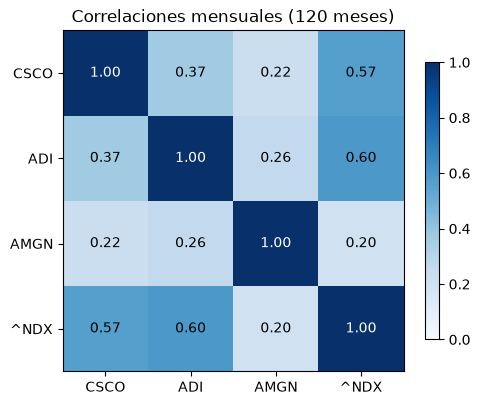

In [9]:
acc = ACC                                             # solo las 3 acciones entran a Markowitz
cov_m = r_m[acc].cov()                                # Σ mensual (la que usamos en P3 y P4)
cov_a = cov_m * k                                     # Σ anual = Σ mensual × 12 (solo para mostrar)
corr_m = r_m.corr()                                   # correlaciones mensuales (incluye ^NDX)

cov_m.to_csv(PROC / "cov_mensual_v2.csv")
corr_m.to_csv(PROC / "corr_mensual_v2.csv")

print("MATRIZ DE VARIANZAS-COVARIANZAS MENSUAL (Σ_m)")
display(cov_m.style.format("{:.5f}"))
print("La misma matriz llevada a un año (Σ_m × 12)")
display(cov_a.style.format("{:.4f}"))

fig, ax = plt.subplots(figsize=(5.5, 4.5))            # mapa de calor de las correlaciones
im = ax.imshow(corr_m, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(corr_m)), corr_m.columns); ax.set_yticks(range(len(corr_m)), corr_m.index)
for i in range(len(corr_m)):
    for j in range(len(corr_m)):
        v = corr_m.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.6 else "black")
ax.set_title("Correlaciones mensuales (120 meses)"); fig.colorbar(im, ax=ax, shrink=0.8); plt.show()

### Lectura de las matrices
En la diagonal de Σ_m está la varianza de cada acción (por ejemplo, ADI 0,00653, que es 8,08 % al cuadrado) y por fuera la covarianza entre pares. Lo que importa para el portafolio son las correlaciones:

| Par | ρ mensual |
|---|---:|
| CSCO – ADI | 0,37 |
| CSCO – AMGN | 0,22 |
| ADI – AMGN | 0,26 |

Ninguna se acerca a 1, y las de AMGN son las más bajas. Esto era lo que buscábamos al cambiar PYPL: una acción de salud que no se mueva al ritmo de la tecnología. Mezclándolas, el riesgo del portafolio va a quedar por debajo del de cada acción sola.

Con el índice, CSCO tiene ρ de 0,57 y ADI de 0,60, pero AMGN apenas 0,20. Esto es bueno para diversificar pero tiene una consecuencia para la cobertura: los futuros son sobre el Nasdaq-100, y una acción que casi no se mueve con el índice va a tener beta baja y no se cubre bien con esos futuros. Lo medimos en el punto 5 (beta) y en el 4 (qué parte del riesgo es sistemático).

Con datos diarios las correlaciones salían más altas (CSCO–AMGN 0,34; AMGN–^NDX 0,39), porque en el día a día todo reacciona junto a las noticias. Mes a mes pesa más el negocio de cada empresa.

## Punto 3 – Portafolio de mínima varianza (R3 – 7 %)

### 3.0 Qué vamos a hacer
El portafolio definitivo es el de **mínima varianza (GMV)**, como quedó en la asesoría: buscamos los pesos que dejan el riesgo más bajo posible, sin importar el retorno.

$$\min_{w}\ \sigma_p = \sqrt{w^\top \Sigma_m\, w} \quad \text{sujeto a} \quad \sum w_i = 1,\quad w_i > 0$$

- $\Sigma_m$ es la matriz de covarianzas mensual del punto 2.
- Regla de pesos (decisión del grupo, 10/11/2026): las tres acciones tienen que participar con más de 0 % y la suma da 100 %. No hay ventas en corto ni techo por acción; dejamos que el optimizador reparta solo. En la primera versión usábamos cotas de 15 %–45 %.
- Para comparar también sacamos el de máximo Sharpe, porque el enunciado pide el Sharpe Ratio. Pero el que sigue a los puntos 4 a 12 es el GMV.

Todo va en unidades mensuales:
- Retorno esperado mensual de cada acción: $\mu_m = e^{\bar r_m} - 1$ (pasar el log promedio a efectivo).
- Tasa libre de riesgo mensual: $r_{f,m} = (1 + 0{,}04929)^{1/12} - 1 = 0{,}4018\,\%$ (^TNX al 30/10/2026 en tasa efectiva).
- Sharpe mensual: $S = (\mu_p - r_{f,m}) / \sigma_p$.

Lo anual es solo de referencia: $\mu_a = (1+\mu_m)^{12} - 1$, $\sigma_a = \sigma_m\sqrt{12}$ y Sharpe anual ≈ Sharpe mensual × √12.

In [15]:
from scipy.optimize import minimize

CAPITAL = 35_000_000                                  # USD a invertir
rf = 0.04929                                          # ^TNX al 30/10/2026 (anual)
rf_m = (1 + rf) ** (1 / 12) - 1                       # tasa libre de riesgo mensual efectiva
mu_m = np.exp(r_m[acc].mean()) - 1                    # retorno esperado mensual de cada acción
S = cov_m.values                                      # Σ mensual (punto 2)
cotas = [(0, 1)] * len(acc)                           # pesos entre 0 y 100 % (sin cortos)
restr = {"type": "eq", "fun": lambda w: w.sum() - 1}  # los pesos suman 100 %
w0 = np.repeat(1 / len(acc), len(acc))                # arrancamos con pesos iguales
opt = {"ftol": 1e-12, "maxiter": 1000}                # tolerancia estricta: mismo resultado en cualquier PC

def ret_p(w): return w @ mu_m.values                  # μ_p = Σ wᵢ·μᵢ (mensual)
def vol_p(w): return np.sqrt(w @ S @ w)               # σ_p = √(wᵀ Σ w) (mensual)
def sharpe(w): return (ret_p(w) - rf_m) / vol_p(w)    # Sharpe mensual

gmv = minimize(vol_p, w0, method="SLSQP", bounds=cotas, constraints=restr, options=opt)
msr = minimize(lambda w: -sharpe(w), w0, method="SLSQP", bounds=cotas, constraints=restr, options=opt)
assert gmv.success and msr.success, "la optimización no convergió"
assert (gmv.x > 1e-6).all(), "ojo: alguna acción quedó en 0 % y la regla pide que las 3 participen"
w_gmv = pd.Series(gmv.x, index=acc)                   # pesos del portafolio definitivo

def ficha(w):                                         # resumen de un portafolio
    return pd.Series({**{f"Peso {a}": x for a, x in zip(acc, w)},
                      **{f"Monto {a} (USD)": x * CAPITAL for a, x in zip(acc, w)},
                      "Retorno mensual": ret_p(w), "Desv. mensual": vol_p(w), "Sharpe mensual": sharpe(w),
                      "Retorno anual (ref.)": (1 + ret_p(w)) ** 12 - 1,
                      "Volatilidad anual (ref.)": vol_p(w) * np.sqrt(12),
                      "Sharpe anual (ref.)": sharpe(w) * np.sqrt(12)})

port = pd.DataFrame({"GMV (definitivo)": ficha(gmv.x), "Máx. Sharpe (comparación)": ficha(msr.x)})
port.to_csv(PROC / "portafolios_markowitz_v2.csv")    # insumo de los puntos 4 a 12

def formato(fila, v):                                 # cada fila con su formato
    if fila.startswith("Monto"): return f"{v:,.2f}"
    if fila.startswith("Sharpe"): return f"{v:.4f}"
    return f"{v:.2%}"
print(f"r_f mensual = {rf_m:.4%} · capital USD {CAPITAL:,.0f} · pesos > 0 y suman 100 %")
display(pd.DataFrame({c: [formato(i, port.at[i, c]) for i in port.index] for c in port}, index=port.index))

# Revisión de la regla: las 3 tienen que quedar con peso positivo
for nombre, w in [("GMV", gmv.x), ("Máx. Sharpe", msr.x)]:
    print(f"{nombre}: peso mínimo = {w.min():.2%} ({acc[w.argmin()]}) → todas participan: {(w > 1e-6).all()}")

r_f mensual = 0.4018% · capital USD 35,000,000 · pesos > 0 y suman 100 %


,GMV (definitivo),Máx. Sharpe (comparación)
Peso CSCO,36.71%,25.09%
Peso ADI,19.37%,41.38%
Peso AMGN,43.92%,33.53%
Monto CSCO (USD),"12,849,261.84","8,782,371.59"
Monto ADI (USD),"6,777,977.92","14,483,363.77"
Monto AMGN (USD),"15,372,760.23","11,734,264.64"
Retorno mensual,1.35%,1.45%
Desv. mensual,5.14%,5.41%
Sharpe mensual,0.1848,0.1945
Retorno anual (ref.),17.49%,18.92%


GMV: peso mínimo = 19.37% (ADI) → todas participan: True
Máx. Sharpe: peso mínimo = 25.09% (CSCO) → todas participan: True


### Lectura de los portafolios
El GMV queda así: **CSCO 36,71 %, ADI 19,37 % y AMGN 43,92 %**. En plata, USD 12.849.261,83 en CSCO, USD 6.777.977,89 en ADI y USD 15.372.760,28 en AMGN.

- Riesgo: 5,14 % mensual (17,81 % al año). Es menos que el de cualquier acción sola (la menos riesgosa, AMGN, tiene 6,72 % mensual) y menos que el promedio ponderado de las tres (7,07 %). Esa diferencia es lo que gana la diversificación.
- Retorno esperado: 1,35 % mensual (17,49 % al año).
- Sharpe: 0,1848 mensual (≈ 0,64 al año).

Tiene lógica que AMGN se lleve el mayor peso: es la menos volátil y la que menos se correlaciona con las otras dos. ADI se lleva el menor peso porque es la más volátil.

Con la regla nueva (pesos mayores a 0 y que sumen 100 %) el optimizador reparte solo y ninguna acción queda en cero. Además, los pesos caen todos entre 15 % y 45 %, así que con las cotas de la primera versión daría exactamente lo mismo. Eso quiere decir que el resultado no depende de la restricción que escojamos.

El de máximo Sharpe (CSCO 25,09 %, ADI 41,38 %, AMGN 33,53 %) le mete más a ADI por su retorno. Gana un poquito en Sharpe (0,1945 contra 0,1848 mensual), pero con más riesgo (5,41 % contra 5,14 %).

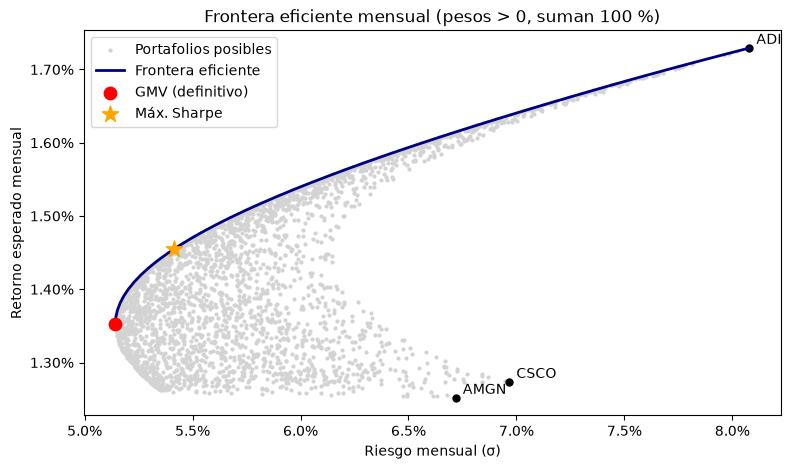

In [16]:
# Frontera eficiente: para cada retorno objetivo, el portafolio de menor riesgo
r_min = ret_p(gmv.x)                                  # el GMV es el punto de menor riesgo
r_max = -minimize(   # el de más retorno posible (todo en ADI)
    lambda w: -ret_p(w), w0, method="SLSQP", bounds=cotas, constraints=restr, options=opt).fun
frontera = []
for r_obj in np.linspace(r_min, r_max, 40):
    rr = [restr, {"type": "eq", "fun": lambda w, r_obj=r_obj: ret_p(w) - r_obj}]
    sol = minimize(vol_p, w0, method="SLSQP", bounds=cotas, constraints=rr, options=opt)
    if sol.success: frontera.append((sol.fun, r_obj))
frontera = np.array(frontera)

# 3.000 portafolios al azar (pesos positivos que suman 1), para ver la nube de opciones
rng = np.random.default_rng(20261030)
azar = rng.dirichlet(np.ones(len(acc)), 3000)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter([vol_p(w) for w in azar], [ret_p(w) for w in azar], s=4, color="lightgrey", label="Portafolios posibles")
ax.plot(frontera[:, 0], frontera[:, 1], color="navy", lw=2, label="Frontera eficiente")
ax.scatter(vol_p(gmv.x), ret_p(gmv.x), color="red", s=80, zorder=3, label="GMV (definitivo)")
ax.scatter(vol_p(msr.x), ret_p(msr.x), color="orange", marker="*", s=150, zorder=3, label="Máx. Sharpe")
for a, s, m in zip(acc, np.sqrt(np.diag(S)), mu_m):
    ax.scatter(s, m, color="black", s=25); ax.annotate(a, (s, m), xytext=(5, 3), textcoords="offset points")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.1%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.2%}"))
ax.set_xlabel("Riesgo mensual (σ)"); ax.set_ylabel("Retorno esperado mensual")
ax.set_title("Frontera eficiente mensual (pesos > 0, suman 100 %)"); ax.legend()
plt.savefig(Path("../outputs/figures") / "frontera_eficiente_v2.png", dpi=150, bbox_inches="tight"); plt.show()

### Portafolio definitivo: mínima varianza (GMV)
Seguimos con el GMV en los puntos 4 a 12: **CSCO 36,71 % · ADI 19,37 % · AMGN 43,92 %**.

Por qué:
- Fue lo que se acordó en la asesoría.
- El objetivo del gerente es invertir 4 años y cubrirse con futuros, o sea que lo que se busca es proteger el capital. El GMV es el de menor riesgo que se puede armar con estas tres acciones.
- El costo es poco: frente al de máximo Sharpe se deja de ganar 0,10 puntos de retorno al mes (1,35 % contra 1,45 %), pero el riesgo baja de 5,41 % a 5,14 %.
- Las tres acciones participan (ninguna queda en cero) sin necesidad de forzar un mínimo o un máximo, así que el resultado no depende de las restricciones.

Algo a tener en cuenta para la cobertura: como AMGN pesa 44 % y casi no se mueve con el Nasdaq-100, la beta del portafolio va a dar baja (alrededor de 0,54, se calcula en el punto 5). Los futuros del índice van a cubrir una parte más pequeña del riesgo que en la primera versión.

## Punto 4 – VaR mensual al 1 % y 5 % (R5 – 8 %)

### 4.0 Qué vamos a calcular
El VaR responde: ¿cuánto es lo máximo que podría perder el portafolio en un mes, con cierta confianza? Al 95 % es la pérdida que solo se supera 1 de cada 20 meses; al 99 %, 1 de cada 100.

Usamos el VaR **paramétrico normal** con los 120 retornos log mensuales del GMV (los mismos pesos del punto 3):

$$r^* = \mu_p - z_c\,\sigma_p \qquad \text{VaR}\,\% = 1 - e^{r^*} \qquad \text{VaR USD} = V_0 \cdot \text{VaR}\,\%$$

- $\mu_p$ y $\sigma_p$: media y desviación del retorno log mensual del portafolio.
- $z_c$: 1,645 al 95 % y 2,326 al 99 %.
- $r^*$ es el retorno log "malo" del corte; como es log, se pasa a pérdida con $1 - e^{r^*}$.
- $V_0$ = USD 35.000.000.

Usamos el normal porque en el punto 2 los retornos mensuales se parecían bastante a una normal. Para no creérnoslo a ciegas, lo comparamos con el VaR histórico (el percentil de los 120 meses reales) y contamos cuántos meses de verdad pasaron el corte (backtesting).

μ mensual = 1.3428% · σ mensual = 5.1423% · ganancia esperada del mes ≈ USD 473,152
Asimetría = 0.03 · curtosis exceso = -0.21 (0 y 0 en una normal)


,z,Retorno crítico (log),VaR (%),VaR (USD),VaR histórico (%),VaR histórico (USD),Meses que lo pasaron,Esperados,p-valor (binomial)
VaR 95% (al 5%),1.6449,-7.12%,6.87%,"2,403,871.07",7.16%,"2,504,910.11",10,6.0,0.079
VaR 99% (al 1%),2.3263,-10.62%,10.08%,"3,526,392.10",8.50%,"2,975,753.42",0,1.2,1.000


Peores 5 meses del portafolio: {'Oct-2020': '-9.73%', 'May-2019': '-8.97%', 'Sep-2022': '-8.53%', 'Feb-2020': '-8.33%', 'Dec-2018': '-7.95%'}


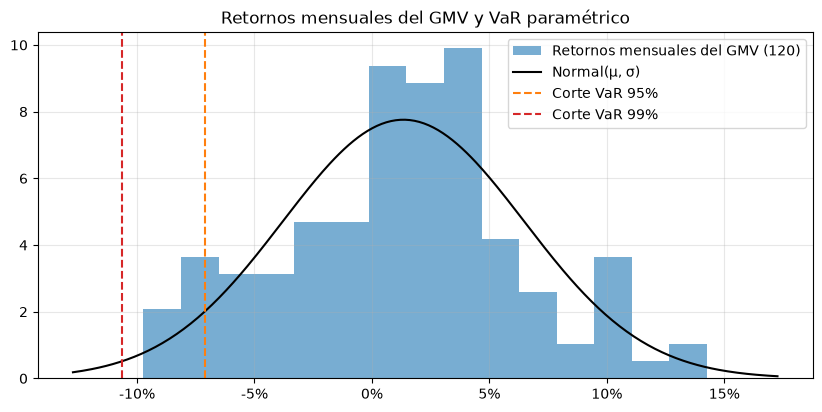

In [17]:
from scipy.stats import norm, binom

V0 = CAPITAL                                          # USD 35.000.000
rp_m = r_m[acc] @ w_gmv                               # retorno log mensual del GMV (120 meses)
mu_p, sig_p = rp_m.mean(), rp_m.std()                 # μ y σ mensuales del portafolio
print(f"μ mensual = {mu_p:.4%} · σ mensual = {sig_p:.4%} · ganancia esperada del mes ≈ USD {V0 * (np.exp(mu_p) - 1):,.0f}")
print(f"Asimetría = {rp_m.skew():.2f} · curtosis exceso = {rp_m.kurt():.2f} (0 y 0 en una normal)")

filas = {}
for c in [0.95, 0.99]:
    z = norm.ppf(c)                                   # 1,645 y 2,326
    r_crit = mu_p - z * sig_p                         # retorno log del corte
    var_pct = 1 - np.exp(r_crit)                      # pérdida en %
    var_hist = 1 - np.exp(rp_m.quantile(1 - c))       # VaR histórico: percentil de los meses reales
    n_exc = int((rp_m < r_crit).sum())                # meses que pasaron el corte
    filas[f"VaR {c:.0%} (al {1 - c:.0%})"] = {
        "z": z, "Retorno crítico (log)": r_crit, "VaR (%)": var_pct, "VaR (USD)": V0 * var_pct,
        "VaR histórico (%)": var_hist, "VaR histórico (USD)": V0 * var_hist,
        "Meses que lo pasaron": n_exc, "Esperados": len(rp_m) * (1 - c),
        "p-valor (binomial)": binom.sf(n_exc - 1, len(rp_m), 1 - c),   # ¿son demasiados?
    }
var_tab = pd.DataFrame(filas).T
var_tab.to_csv(PROC / "var_mensual_v2.csv")           # insumo de los puntos 10 y 11

display(var_tab.style.format({"z": "{:.4f}", "Retorno crítico (log)": "{:.2%}", "VaR (%)": "{:.2%}",
        "VaR (USD)": "{:,.2f}", "VaR histórico (%)": "{:.2%}", "VaR histórico (USD)": "{:,.2f}",
        "Meses que lo pasaron": "{:.0f}", "Esperados": "{:.1f}", "p-valor (binomial)": "{:.3f}"}))
print("Peores 5 meses del portafolio:", {d.strftime("%b-%Y"): f"{v:.2%}" for d, v in rp_m.nsmallest(5).items()})

fig, ax = plt.subplots(figsize=(10, 4.5))             # retornos reales vs. la normal y los cortes
ax.hist(rp_m, bins=15, density=True, alpha=0.6, label="Retornos mensuales del GMV (120)")
x = np.linspace(rp_m.min() - 0.03, rp_m.max() + 0.03, 300)
ax.plot(x, norm.pdf(x, mu_p, sig_p), "k-", label="Normal(μ, σ)")
for c, col in [(0.95, "tab:orange"), (0.99, "tab:red")]:
    ax.axvline(filas[f"VaR {c:.0%} (al {1 - c:.0%})"]["Retorno crítico (log)"], color=col, ls="--", label=f"Corte VaR {c:.0%}")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Retornos mensuales del GMV y VaR paramétrico"); ax.legend(); ax.grid(alpha=0.3)
fig.savefig("../outputs/figures/var_mensual_v2.png", dpi=150, bbox_inches="tight"); plt.show()

### Lectura del VaR
El GMV espera ganar 1,34 % al mes (unos USD 473.000) con una desviación de 5,14 %. Sus retornos mensuales casi no tienen asimetría (0,03) ni colas gordas (−0,21), así que el supuesto normal se sostiene.

- **VaR 95 % (al 5 %): 6,87 % ≈ USD 2.403.871.** En 19 de cada 20 meses no deberíamos perder más que eso. El mes que sobra puede ser peor.
- **VaR 99 % (al 1 %): 10,08 % ≈ USD 3.526.392.** Es la pérdida de un mes muy malo, de esos que pasan una vez cada 100 meses (más de 8 años).

Comparación con la realidad:
- El VaR histórico al 95 % da 7,16 % (USD 2,50 M), muy parecido al normal. Al 99 % da 8,50 %, pero con 120 meses ese percentil sale de uno o dos datos, así que no le creemos mucho.
- Backtesting: 10 de los 120 meses perdieron más que el VaR 95 % y se esperaban 6. Son unos poquitos más, pero el p-valor de 0,08 dice que no es suficiente para decir que el modelo falla. Ningún mes pasó el VaR 99 % (se esperaba algo más de 1).
- El peor mes fue octubre de 2020 (−9,73 % log), que no alcanza el corte del 99 %.

Frente a la versión 1 (máximo Sharpe con PYPL), el VaR 95 % baja de USD 2,88 M a USD 2,40 M. Eso es justo lo que se busca con el portafolio de mínima varianza.

Para la cobertura, el VaR nos dice cuánto podemos perder en un mes malo. La pregunta del 4.2 es qué parte de esa pérdida se puede quitar con futuros del Nasdaq-100.

### 4.2 ¿Cuánto del VaR se puede quitar con futuros?
Un futuro sobre el Nasdaq-100 solo cubre lo que el portafolio se mueve **con el índice**. Para separarlo usamos el modelo de mercado:

$$r_p = \alpha + \beta\, r_{NDX} + \varepsilon \quad\Rightarrow\quad \sigma_p^2 = \beta^2\sigma_{NDX}^2 + \sigma_\varepsilon^2$$

- $\beta^2\sigma_{NDX}^2$ es el riesgo **sistemático**: se mueve con el mercado y es lo que se puede cubrir.
- $\sigma_\varepsilon^2$ es el riesgo **específico** de las tres empresas: el futuro no lo toca.
- $R^2 = \rho(r_p, r_{NDX})^2$ dice qué fracción del riesgo es sistemática.

Con eso calculamos el VaR que quedaría con una cobertura perfecta del riesgo sistemático, es decir, dejando solo $\sigma_\varepsilon$.

In [18]:
r_ndx_m = r_m["^NDX"]                                 # retornos log mensuales del Nasdaq-100
beta_m = rp_m.cov(r_ndx_m) / r_ndx_m.var()            # β = Cov(rp, rm) / Var(rm) (preliminar; el P5 la detalla)
R2 = rp_m.corr(r_ndx_m) ** 2                          # fracción del riesgo explicada por el índice
sig_sis = np.sqrt(R2) * sig_p                         # σ sistemática (= β · σ_NDX)
sig_esp = np.sqrt(1 - R2) * sig_p                     # σ específica: lo que la cobertura no quita

descomp = pd.DataFrame({
    "Varianza mensual": [sig_p**2, sig_sis**2, sig_esp**2],
    "% de la varianza": [1, R2, 1 - R2],
    "σ mensual": [sig_p, sig_sis, sig_esp],
}, index=["Total del portafolio", "Sistemática (cubrible con futuros)", "Específica (no cubrible)"])
print(f"β mensual = {beta_m:.4f} · ρ con ^NDX = {np.sqrt(R2):.2f} · R² = {R2:.4f}")
display(descomp.style.format({"Varianza mensual": "{:.6f}", "% de la varianza": "{:.2%}", "σ mensual": "{:.2%}"}))

comp = {}                                             # VaR sin cobertura vs. con cobertura ideal
for c in [0.95, 0.99]:
    z = norm.ppf(c)
    var_sin = 1 - np.exp(mu_p - z * sig_p)            # con todo el riesgo
    var_con = 1 - np.exp(mu_p - z * sig_esp)          # solo queda el riesgo específico
    comp[f"VaR {c:.0%}"] = {"Sin cobertura (%)": var_sin, "Sin cobertura (USD)": V0 * var_sin,
                            "Cubierto (%)": var_con, "Cubierto (USD)": V0 * var_con,
                            "Reducción (USD)": V0 * (var_sin - var_con), "Reducción (%)": 1 - var_con / var_sin}
comp = pd.DataFrame(comp).T
comp.to_csv(PROC / "var_cubierto_vs_sin_v2.csv")
display(comp.style.format("{:,.2f}", subset=["Sin cobertura (USD)", "Cubierto (USD)", "Reducción (USD)"])
            .format("{:.2%}", subset=["Sin cobertura (%)", "Cubierto (%)", "Reducción (%)"]))
print(f"Exposición al índice que hay que cubrir ≈ β × V0 = {beta_m:.4f} × {V0:,.0f} = USD {beta_m * V0:,.2f}")

β mensual = 0.5401 · ρ con ^NDX = 0.58 · R² = 0.3327


,Varianza mensual,% de la varianza,σ mensual
Total del portafolio,0.002644,100.00%,5.14%
Sistemática (cubrible con futuros),0.000880,33.27%,2.97%
Específica (no cubrible),0.001765,66.73%,4.20%


,Sin cobertura (%),Sin cobertura (USD),Cubierto (%),Cubierto (USD),Reducción (USD),Reducción (%)
VaR 95%,6.87%,"2,403,871.07",5.41%,"1,895,079.45","508,791.62",21.17%
VaR 99%,10.08%,"3,526,392.10",8.08%,"2,829,339.33","697,052.77",19.77%


Exposición al índice que hay que cubrir ≈ β × V0 = 0.5401 × 35,000,000 = USD 18,905,159.98


### Lectura: el VaR como base de la cobertura
La correlación del GMV con el Nasdaq-100 es 0,58, entonces **R² = 0,33**: solo un tercio del riesgo del portafolio es sistemático (σ de 2,97 % al mes) y se puede cubrir con futuros del índice. Los otros dos tercios (σ de 4,20 %) son riesgo propio de CSCO, ADI y AMGN, y un futuro del Nasdaq-100 no los quita.

Con una cobertura perfecta de la parte sistemática:
- VaR 95 %: pasa de USD 2.403.871 a USD 1.895.079 (baja 21 %).
- VaR 99 %: pasa de USD 3.526.392 a USD 2.829.339 (baja 20 %).

Esto es consecuencia directa de haber escogido el GMV con 44 % en AMGN. El portafolio arriesga menos sin cubrirse (VaR 95 % de 2,40 M contra 2,88 M en la v1), pero una parte menor de ese riesgo es cubrible (33 % contra 56 % en la v1). Al final, ya cubierto, queda en un nivel parecido al de la v1 (USD 1,90 M contra 1,79 M). La diversificación ya hizo buena parte del trabajo que antes le tocaba a los futuros.

El monto a cubrir no son los USD 35 millones, sino la exposición equivalente al índice: β × V0 = 0,5401 × 35 M ≈ **USD 18,9 millones**. Sobre ese monto se calcula el número de contratos en el punto 6.

## Punto 5 – Betas CAPM y beta del portafolio (R6 – 8 %)

### 5.0 Qué es la beta
La beta dice cuánto se mueve una acción cuando el mercado se mueve 1 %. Si β = 0,5, cuando el Nasdaq-100 cae 10 % la acción cae en promedio 5 %.

La sacamos con una regresión de los retornos log mensuales de cada acción contra los del ^NDX (los mismos 120 meses del punto 2):

$$r_i = \alpha_i + \beta_i\, r_{NDX} + \varepsilon_i \qquad \beta_i = \frac{Cov(r_i, r_{NDX})}{Var(r_{NDX})}$$

La beta del portafolio es el promedio ponderado con los pesos del GMV, como pide el enunciado:

$$\beta_p = \sum w_i\,\beta_i$$

Con la beta también armamos el CAPM, que dice cuánto debería rendir cada acción según su riesgo de mercado: $E(r_i) = r_f + \beta_i\,[E(r_m) - r_f]$. Todo va en mensual: $r_{f,m}$ = 0,4018 % y $E(r_m) = e^{\bar r_{NDX}} - 1$.

In [20]:
from scipy.stats import linregress

mkt = "^NDX"
E_rm = np.exp(r_m[mkt].mean()) - 1                    # retorno esperado mensual del mercado
filas = {}
for a in acc:
    reg = linregress(r_m[mkt], r_m[a])                # regresión mensual: r_a = α + β · r_NDX + ε
    capm = rf_m + reg.slope * (E_rm - rf_m)           # lo que "debería" rendir según el CAPM (mensual)
    filas[a] = {
        "Peso GMV": w_gmv[a],
        "β": reg.slope, "Error est. β": reg.stderr, "t de β": reg.slope / reg.stderr,
        "R²": reg.rvalue ** 2,                        # qué parte del riesgo de la acción explica el índice
        "α mensual": reg.intercept,                   # lo que rinde de más (o de menos) que el mercado
        "E(r) CAPM mensual": capm,
        "E(r) histórico mensual": mu_m[a],            # del punto 3
        "E(r) CAPM anual (ref.)": (1 + capm) ** 12 - 1,
        "E(r) histórico anual (ref.)": (1 + mu_m[a]) ** 12 - 1,
    }
betas = pd.DataFrame(filas).T

beta_p = (betas["Peso GMV"] * betas["β"]).sum()                        # βp = Σ wi · βi
beta_p_reg = linregress(r_m[mkt], rp_m).slope                          # verificación: regresión del portafolio
capm_p = rf_m + beta_p * (E_rm - rf_m)
betas.loc["Portafolio GMV"] = {"Peso GMV": 1, "β": beta_p, "E(r) CAPM mensual": capm_p,
                               "E(r) histórico mensual": ret_p(w_gmv.values),
                               "E(r) CAPM anual (ref.)": (1 + capm_p) ** 12 - 1,
                               "E(r) histórico anual (ref.)": (1 + ret_p(w_gmv.values)) ** 12 - 1}
betas.to_csv(PROC / "betas_capm_v2.csv")              # insumo del punto 6

print(f"Betas mensuales contra ^NDX · 120 meses · E(rm) mensual = {E_rm:.2%} · rf mensual = {rf_m:.4%}")
display(betas.style.format("{:.4f}", subset=["β", "Error est. β"], na_rep="–")
             .format("{:.2f}", subset=["t de β"], na_rep="–")
             .format("{:.2%}", subset=["Peso GMV", "R²", "α mensual", "E(r) CAPM mensual", "E(r) histórico mensual",
                                       "E(r) CAPM anual (ref.)", "E(r) histórico anual (ref.)"], na_rep="–"))
print(f"βp = Σ wi·βi = {beta_p:.4f} · verificación con regresión directa del portafolio = {beta_p_reg:.4f}")

Betas mensuales contra ^NDX · 120 meses · E(rm) mensual = 1.49% · rf mensual = 0.4018%


,Peso GMV,β,Error est. β,t de β,R²,α mensual,E(r) CAPM mensual,E(r) histórico mensual,E(r) CAPM anual (ref.),E(r) histórico anual (ref.)
CSCO,36.71%,0.7173,0.0964,7.44,31.95%,0.20%,1.18%,1.27%,15.17%,16.40%
ADI,19.37%,0.8774,0.1087,8.07,35.56%,0.42%,1.36%,1.73%,17.57%,22.84%
AMGN,43.92%,0.2434,0.1104,2.21,3.96%,0.88%,0.67%,1.25%,8.31%,16.10%
Portafolio GMV,100.00%,0.5401,–,–,–,–,0.99%,1.35%,12.56%,17.49%


βp = Σ wi·βi = 0.5401 · verificación con regresión directa del portafolio = 0.5401


### Lectura de las betas
- **CSCO (β = 0,72)** y **ADI (β = 0,88)** se mueven con el mercado pero un poco menos que él. Las dos betas son claramente distintas de cero (t de 7,4 y 8,1), y el índice explica más o menos un tercio de su riesgo (R² de 0,32 y 0,36).
- **AMGN (β = 0,24)** casi no sigue al Nasdaq-100. El índice explica solo el 4 % de su riesgo (R² = 0,04), y su beta apenas es significativa (t = 2,2). Tiene sentido: es una biotecnológica dentro de un índice lleno de tecnología.

**CAPM.** Las tres rindieron más de lo que el CAPM les exigía por su riesgo de mercado: CSCO 16,4 % al año contra 15,2 % del CAPM, ADI 22,8 % contra 17,6 % y AMGN 16,1 % contra 8,3 %. Todas tienen α positivo. El caso de AMGN es el más llamativo: con tan poca beta, el CAPM le pide poco, y ella rindió casi el doble. Ojo, que con 120 meses estos α son estimaciones con bastante ruido.

### 5.2 Beta del portafolio y exposición sistemática
Con los pesos del GMV:

$$\beta_p = 0{,}3671(0{,}7173) + 0{,}1937(0{,}8774) + 0{,}4392(0{,}2434) = 0{,}5401$$

Abajo miramos qué significa esto en plata: cuánto se movería el portafolio de USD 35 millones si el Nasdaq-100 se mueve, solo por el efecto del mercado ($\Delta V \approx \beta_p \cdot \Delta r_{NDX} \cdot V_0$).

In [21]:
expo_sis = beta_p * V0                                # USD equivalentes invertidos en el índice
aporte = (w_gmv * betas.loc[acc, "β"]) / beta_p       # cuánto aporta cada acción a la beta del portafolio
print(f"Exposición sistemática = βp × V0 = {beta_p:.4f} × {V0:,.0f} = USD {expo_sis:,.2f}")
print("Aporte de cada acción a βp:", {a: f"{v:.1%}" for a, v in aporte.items()})

movs = [-0.20, -0.10, -0.05, 0.05, 0.10, 0.20]        # movimientos del índice en un mes
sens = pd.DataFrame({"Movimiento del ^NDX": movs,
                     "Cambio esperado del portafolio (%)": [beta_p * m for m in movs],
                     "Cambio esperado (USD)": [beta_p * m * V0 for m in movs]})
display(sens.style.format({"Movimiento del ^NDX": "{:+.0%}", "Cambio esperado del portafolio (%)": "{:+.2%}",
                           "Cambio esperado (USD)": "{:+,.0f}"}).hide(axis="index"))

Exposición sistemática = βp × V0 = 0.5401 × 35,000,000 = USD 18,905,159.98
Aporte de cada acción a βp: {'CSCO': '48.7%', 'ADI': '31.5%', 'AMGN': '19.8%'}


Movimiento del ^NDX,Cambio esperado del portafolio (%),Cambio esperado (USD)
-20%,-10.80%,"-3,781,032"
-10%,-5.40%,"-1,890,516"
-5%,-2.70%,"-945,258"
+5%,+2.70%,"+945,258"
+10%,+5.40%,"+1,890,516"
+20%,+10.80%,"+3,781,032"


### Lectura de la exposición sistemática
La beta del portafolio da **0,5401**, igual por las dos vías (promedio ponderado y regresión directa). Es la misma que salió en el punto 4.

En plata, los USD 35 millones se comportan frente al mercado como si tuviéramos **USD 18,9 millones metidos en el Nasdaq-100**. Si el índice cae 10 % en un mes, el portafolio pierde en promedio 5,4 % (unos USD 1,89 millones) solo por el efecto del mercado. Si cae 20 %, pierde alrededor de USD 3,78 millones. Esa es la exposición que vamos a cubrir con futuros cortos en el punto 6.

De dónde sale esa beta: CSCO aporta el 49 %, ADI el 31 % y AMGN solo el 20 %, aunque AMGN es la que más pesa en el portafolio (44 %).

Comparado con la versión 1 (βp = 0,82 mensual con máximo Sharpe y PYPL), ahora la beta es mucho más baja. Eso tiene dos caras:
- El portafolio sufre menos cuando el mercado cae y necesita menos contratos para cubrirse.
- Pero, como vimos en el punto 4, solo un tercio del riesgo total depende del índice (R² = 0,33). El resto es riesgo propio de cada empresa, y ese no lo quita ningún futuro del Nasdaq-100.

### Resumen del bloque de portafolio (puntos 1 a 5)
- Acciones: CSCO, ADI y AMGN, todas del Nasdaq-100.
- Portafolio GMV: CSCO 36,71 % · ADI 19,37 % · AMGN 43,92 % (USD 12,85 M / 6,78 M / 15,37 M).
- Retorno esperado de 1,35 % mensual y riesgo de 5,14 % mensual.
- VaR mensual: 95 % USD 2,40 M y 99 % USD 3,53 M.
- βp = 0,5401: exposición sistemática de USD 18,9 M, que es lo que se cubre con futuros en `02_futuros_cobertura`.